<a href="https://colab.research.google.com/github/mib-a/ML-DL/blob/main/2%20Machine%20Learning/Module%2006%20Distribution%20%26%20Outlier/2_2_6_Data_Distribution_%26_Outliers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#3 Starter, Train Test and Handling Missing Values

### Theory Discussed:
- imputation after train_test_split (to prevent data leakage)
- fit_transform for train, only transform for test (to prevent data leakge)
- ravel() and scikit learn 2D array returning (must for categorical)

### Workflow of this file:
- Dataset Loading (titanic_updated.csv)
- dropping unnecessary and target col
- train test split
- missing value imputation  
  - panda : age
  - scikit learn :
    - age: mean, median (no ravel())
    - embarked: ravel ()
    - cabin: indicator

In [83]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

In [84]:
df = pd.read_csv('titanic_data_updated.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,no,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,no,second,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,yes,first,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,no,third,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,yes,first,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


### 3.3 Feature Engineering Starter

#### Dropping Unnecessary Columns

In [85]:
df.drop(['PassengerId','Name','Ticket'],
        axis=1, # columns to be searched.
        inplace=True) # changes will be saved in the main dataset

In [86]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,no,third,male,22.0,1,0,7.2500,NaN,S
1,yes,first,female,38.0,1,0,71.2833,C85,C
2,yes,third,female,26.0,0,0,7.9250,NaN,S
3,yes,first,female,35.0,1,0,53.1000,C123,S
4,no,third,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...
886,no,second,male,27.0,0,0,13.0000,NaN,S
887,yes,first,female,19.0,0,0,30.0000,B42,S
888,no,third,female,NaN,1,2,23.4500,NaN,S
889,yes,first,male,26.0,0,0,30.0000,C148,C


#### Dropping the Label (target column)

In [87]:
X = df.drop(['Survived'],axis=1)
X

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,third,male,22.0,1,0,7.2500,NaN,S
1,first,female,38.0,1,0,71.2833,C85,C
2,third,female,26.0,0,0,7.9250,NaN,S
3,first,female,35.0,1,0,53.1000,C123,S
4,third,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...
886,second,male,27.0,0,0,13.0000,NaN,S
887,first,female,19.0,0,0,30.0000,B42,S
888,third,female,NaN,1,2,23.4500,NaN,S
889,first,male,26.0,0,0,30.0000,C148,C


#### Dropping Target Column dataframe

In [88]:
y = df['Survived']
y

,Survived
0,no
1,yes
2,yes
3,yes
4,no
...,...
886,no
887,yes
888,no
889,yes


### 3.5 Train Test Split Code

In [89]:
X_train, X_test, y_train, y_test = train_test_split(X,y,
                                                    test_size=0.2, # 20% of total data will be used for testing
                                                    random_state=42) # for reproducibility

#### Display & Print X/y_train/test

In [90]:
print(f"y_train: \n{y_train}\n")
display(X_train)
# print(f"X_test: \n{X_test}\n")
# print(f"y_test: \n{y_test}\n")

y_train: 
331     no
733     no
382     no
704     no
813     no
      ... 
106    yes
270     no
860     no
435    yes
102     no
Name: Survived, Length: 712, dtype: object



,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
331,first,male,45.5,0,0,28.5000,C124,S
733,second,male,23.0,0,0,13.0000,NaN,S
382,third,male,32.0,0,0,7.9250,NaN,S
704,third,male,26.0,1,0,7.8542,NaN,S
813,third,female,6.0,4,2,31.2750,NaN,S
...,...,...,...,...,...,...,...,...
106,third,female,21.0,0,0,7.6500,NaN,S
270,first,male,NaN,0,0,31.0000,NaN,S
860,third,male,41.0,2,0,14.1083,NaN,S
435,first,female,14.0,1,2,120.0000,B96 B98,S


#### Note: Imputation after train_test-split
In imputation, we use mean, median, standard deviation etc. If you impute the whole dataset before tts, model will be able to see through all those test data and will encounter a data leakage. Your model's predictions on this exact dataset will be exceptionally well but on any unseen data it won't be ab;e to predict anything as it has learnt zero thing (overfitting).

### 3.7 Numerical Imputation with Pandas

#### Checkin for null values in X_train/test

In [91]:
X_train.isnull().sum()

,0
Pclass,0
Sex,0
Age,140
SibSp,0
Parch,0
Fare,0
Cabin,553
Embarked,2


In [92]:
X_test.isnull().sum()

,0
Pclass,0
Sex,0
Age,37
SibSp,0
Parch,0
Fare,0
Cabin,134
Embarked,0


#### Visualize Age before Imputation

<Axes: xlabel='Age', ylabel='Density'>

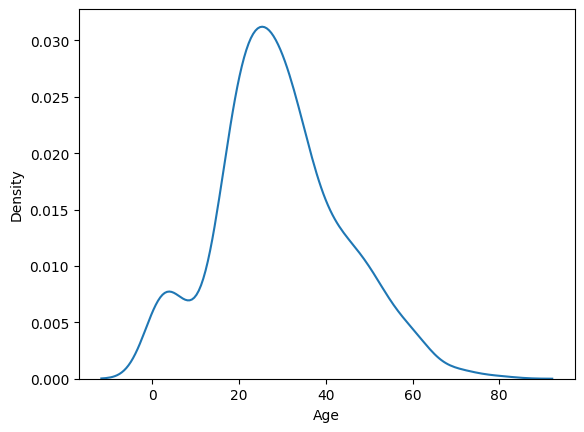

In [93]:
sns.kdeplot(data = X_train, x = "Age")

#### Imputing age with mean value

In [94]:
#mean impute

age_mean = X_train['Age'].mean() # mean of age col of X_train

# df["new_col"] = df["present_col"].fillna(age_mean) : fillna = fill all the values which are NaN (missing)

# impute both of X_train, y_train
X_train['age_mean_imputor'] = X_train['Age'].fillna(age_mean)
X_test['age_mean_imputor'] = X_test['Age'].fillna(age_mean)

<Axes: xlabel='age_mean_imputor', ylabel='Density'>

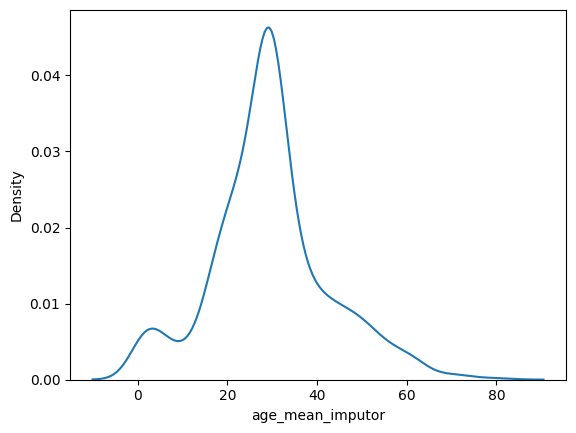

In [95]:
sns.kdeplot(data = X_train, x = "age_mean_imputor")

#### Imputing age with median

In [96]:
#median impute

age_median = X_train['Age'].median()

X_train['age_median_imputor'] = X_train['Age'].fillna(age_median)

X_test['age_median_imputor'] = X_test['Age'].fillna(age_median)

<Axes: xlabel='age_median_imputor', ylabel='Density'>

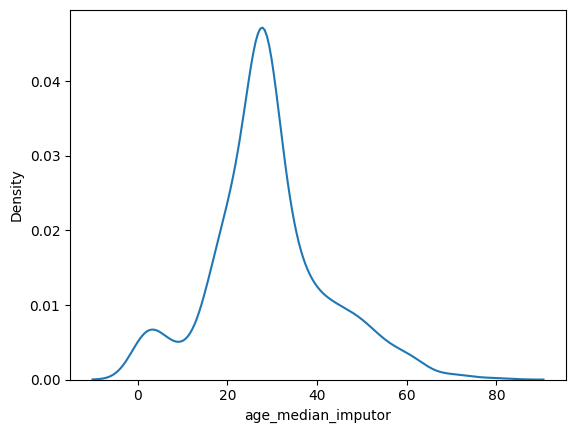

In [97]:
sns.kdeplot(data = X_train, x = "age_median_imputor")

### 3.8 Numerical Imputation Simple Imputer

In [98]:
from sklearn.impute import SimpleImputer

age_imputer = SimpleImputer(missing_values=np.nan , strategy='mean') # ~= fillna (df[""].mean)
X_train["Age"] = age_imputer.fit_transform(X_train[["Age"]])

X_train.sample(2)

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,age_mean_imputor,age_median_imputor
297,first,female,2.000000,1,2,151.55,C22 C26,S,2.000000,2.0
459,third,male,29.498846,0,0,7.75,NaN,Q,29.498846,28.0


Explanation: Age and age_mean_imputer are the same, same goes for median. You can change mean to median and compare it with age_median_imputor

#### The less cols (= the less dimensions) the better

In [99]:
print(f"Num of sum values in Age: {X_train.isnull().sum()}")

# dropping unnecessary cols
X_train.drop(['age_mean_imputor','age_median_imputor'],axis=1,inplace=True)

X_train

Num of sum values in Age: Pclass                  0
Sex                     0
Age                     0
SibSp                   0
Parch                   0
Fare                    0
Cabin                 553
Embarked                2
age_mean_imputor        0
age_median_imputor      0
dtype: int64


,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
331,first,male,45.500000,0,0,28.5000,C124,S
733,second,male,23.000000,0,0,13.0000,NaN,S
382,third,male,32.000000,0,0,7.9250,NaN,S
704,third,male,26.000000,1,0,7.8542,NaN,S
813,third,female,6.000000,4,2,31.2750,NaN,S
...,...,...,...,...,...,...,...,...
106,third,female,21.000000,0,0,7.6500,NaN,S
270,first,male,29.498846,0,0,31.0000,NaN,S
860,third,male,41.000000,2,0,14.1083,NaN,S
435,first,female,14.000000,1,2,120.0000,B96 B98,S


#### Note: Fit & Transform
- Fit : going through the whole model, learning it's mean, median etc from the dataset.
- Transform : as the direction of simple imputer, it will transform the dataset with that learnt statistics (like imputing *missing values* with *mean / median*)

- Problem: We do fit only on the train data as model can see it, can learn necessary statistics from it. Train and test datasets have a very little difference in their statistics. Almost identical. So, the model learn the statistics from the training data and use it to transform both train and test data. if you fit the test data too, the model will be able to see the test dataset,and same as before data leakage will occur.



In [100]:
X_test['Age'] = age_imputer.transform(X_test[['Age']])

X_test.isnull().sum()

,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Cabin,134
Embarked,0
age_mean_imputor,0
age_median_imputor,0


In [101]:
X_test.drop(['age_mean_imputor','age_median_imputor'],axis=1,inplace=True)
X_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
709,third,male,29.498846,1,1,15.2458,NaN,C
439,second,male,31.000000,0,0,10.5000,NaN,S
840,third,male,20.000000,0,0,7.9250,NaN,S
720,second,female,6.000000,0,1,33.0000,NaN,S
39,third,female,14.000000,1,0,11.2417,NaN,C
...,...,...,...,...,...,...,...,...
433,third,male,17.000000,0,0,7.1250,NaN,S
773,third,male,29.498846,0,0,7.2250,NaN,C
25,third,female,38.000000,1,5,31.3875,NaN,S
84,second,female,17.000000,0,0,10.5000,NaN,S


### 3.9 Categorical Value Imputation

#### Imputing with mode (most frequent)

In [102]:
embarked_imputer = SimpleImputer(missing_values=np.nan , strategy='most_frequent')

X_train['Embarked'] = embarked_imputer.fit_transform(X_train[['Embarked']]).ravel()
X_test['Embarked'] = embarked_imputer.transform(X_test[['Embarked']]).ravel()

#### Note: `ravel():`
Scikit-Learn expects and returns a 2D array, series (columns) of pandas are 1D arrays. So,

`df[col] = imputer.fit_transform(df[["col"]]).ravel()`
- `df[['col']]` : turning the col into 2D array by double [], so scikit learn can work with that.
- `.ravel()` : pandas can not work with 2D and scikit returned 2D array, so to ***flatten*** it to 1D, we use ravel()

Exception:
- sometimes **numerical columns** *(age)* or integer type categorical columns *doesnt need `.ravel()`*. Panda converts them itself. But still it can throw some errors or warning. Completely depends on pandas version. But for a categorical col, you will always need ravel (*embarked*)

In [103]:
X_train.isnull().sum()
X_test.isnull().sum()

,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Cabin,134
Embarked,0


#### Imputing with constant and indicator

In [104]:
cabin_imputer = SimpleImputer(missing_values=np.nan, # which to impute: all the NaN (nan) values
                              strategy='constant', # by what strategy to impute: use a constant
                              fill_value='Missing', # what constant? : most frequent (mode) / "missing"
                              add_indicator=True) # add another col to address which rows had NaN values

# fit & or transform into two columns because add_indicator=True returns both imputed values and indicators
X_train[['Cabin', 'cabin_missing_indicator']] = cabin_imputer.fit_transform(X_train[['Cabin']])
X_test[['Cabin', 'cabin_missing_indicator']] = cabin_imputer.transform(X_test[['Cabin']])

X_train.sample(5)

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,cabin_missing_indicator
248,first,male,37.000000,1,1,52.5542,D35,S,False
62,first,male,45.000000,1,0,83.4750,C83,S,False
99,second,male,34.000000,1,0,26.0000,Missing,S,True
264,third,female,29.498846,0,0,7.7500,Missing,Q,True
148,second,male,36.500000,0,2,26.0000,F2,S,False


Check for null values again

In [105]:
X_train.isnull().sum()

,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Cabin,0
Embarked,0
cabin_missing_indicator,0


In [106]:
X_test.isnull().sum()

,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Cabin,0
Embarked,0
cabin_missing_indicator,0


#5 Data Distribution
3 Types of Distribution are possible
1. Normal/gaussian Distribution / Bell curve:
    - symmetric around the center
    - mode = median = mean = center point
    - Dependence on mean & std:
      - mean change: graph shifts to left (mean small) or right (mean big)
      - standard deviation change: increase -> graph gets flatter
    - The empirical Rule (68-95-99.7) after conversion:  
      - from z score -1 to +1 or $(\mu + 1 \times \sigma)$ to $(\mu - 1 \times \sigma)$ : $34.13\% \times 2 = 68.26 \% $ of the total area of the graph is situated. So, almost 68% data is here.
      - $(\mu + 2 \times \sigma)$ to $(\mu - 2 \times \sigma)$ : $ 68.26 \% + 13.59\% \times 2 = 95.44 \% $ of the total area of the graph.
      - $(\mu + 3 \times \sigma)$ to $(\mu - 3 \times \sigma)$ : $95.44\% + 2.14\% \times 2 = 99.72\%$ of the total area of the graph.
      - $(\mu + 4 \times \sigma)$ to $(\mu - 4 \times \sigma)$ : $99.72\% + 0.13\% \times 2 = 99.98\%$ of the total area of the graph.



2. Skewed Distribution:
    - Right Skewed:
      - longer tails on the righ side.
      - mode < median  < mean.
      - high value more
    - Left Skewed:
      - longer tails on the left side.
      - mode > median > mean
      - low value more


#6 Outliers Detection & Handling

## Note
## What is an outlier?
- the odd/extreme one or the anamoly
  - An outlier is a data point that differs significantly from other observations in your dataset.
- Example & why they matters:
   - **The Ugly Outliers -> Skewed Averages & Model Disruption** : a billionaire moving into a middle-class neighborhood : now that neighbourhood's avg income will go up
   - **Positive Outliers -> Hidden Insight** : a sudden spike in website traffic due to a viral video : so we can learn which kind of video people like the most
   - **The Bad outliers -> Anamoly Detection** : a $5,000 international swipe at 3 AM when the user usually spends 20 dollars locally = fraud alert

## Dealing with Outliers:
- Outlier Detection:
  - Z-Score : $Z > |3|$ = outliers; $z_i= \frac{x_i-\mu}{σ}$ ($\mu = mean$ & $\sigma = Standard Deviation$)
  - IQR (Interquartile Range)

- Outlier Handling:
  - Delete/Trim
  - Capping: Winsorization Method

## Outlier Detection

##6.4 Using Z-Score
- Outlier Sensitive : heavily depends on mean, outlier shifts mean, the whole graph shifts, so does the area.
- KDE Plot & histogram (Data Density)

### Z_score formula
$$z = \frac{x - \mu}{\sigma}$$

Here,
- z: The z-score (standard score)
- x: The raw data point or value : $x_i$
- μ: The population mean : $\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$
- σ: The population standard deviation : $\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_i - \mu)^2}$

### Outlier Detection:
- if the z score value of something is more than 3 (99.72%), that's an outlier.







### Age with Z Score

In [107]:
# pre requisite for z score
mean_of_age = X_train['Age'].mean() # the mean
std_of_age = X_train['Age'].std() # the standard deviation

# zscore of age col
X_train['zscore_Age'] = (X_train['Age'] - mean_of_age) / std_of_age

X_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,cabin_missing_indicator,zscore_Age
331,first,male,45.500000,0,0,28.5000,C124,S,False,1.231398e+00
733,second,male,23.000000,0,0,13.0000,Missing,S,True,-5.001304e-01
382,third,male,32.000000,0,0,7.9250,Missing,S,True,1.924808e-01
704,third,male,26.000000,1,0,7.8542,Missing,S,True,-2.692600e-01
813,third,female,6.000000,4,2,31.2750,Missing,S,True,-1.808396e+00
...,...,...,...,...,...,...,...,...,...,...
106,third,female,21.000000,0,0,7.6500,Missing,S,True,-6.540440e-01
270,first,male,29.498846,0,0,31.0000,Missing,S,True,2.734055e-16
860,third,male,41.000000,2,0,14.1083,Missing,S,True,8.850920e-01
435,first,female,14.000000,1,2,120.0000,B96 B98,S,False,-1.192742e+00


Explanation:
The new column zscore_Age has appeared. Use the formula urself and determine the zscore for the first 5 ones and check if they match.

#### Viewing the age outliers

In [108]:
outliers_age = X_train[abs(X_train['zscore_Age']) >3] # |z_score| > 3 = outlier

print(len(outliers_age))

display(outliers_age)

5


,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,cabin_missing_indicator,zscore_Age
116,third,male,70.5,0,0,7.750,Missing,Q,True,3.155317
745,first,male,70.0,1,1,71.000,B22,S,False,3.116839
630,first,male,80.0,0,0,30.000,A23,S,False,3.886407
851,third,male,74.0,0,0,7.775,Missing,S,True,3.424666
672,second,male,70.0,0,0,10.500,Missing,S,True,3.116839


There are only 5 samples (rows) with an extreme age. All are older than or equal to 70. So, applying z-score these 5 are our outliers.

### Fare with Z Score

In [109]:
mean_of_fare = X_train['Fare'].mean()
std_of_fare = X_train['Fare'].std()

X_train['zscore_Fare'] = (X_train['Fare']-mean_of_fare)/std_of_fare

X_train

outliers_fare = X_train[abs(X_train['zscore_Fare']) >3]

print(len(outliers_fare))

display(outliers_fare)

17


,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,cabin_missing_indicator,zscore_Age,zscore_Fare
118,first,male,24.000000,0,1,247.5208,B58 B60,C,False,-4.231736e-01,4.135780
716,first,female,38.000000,0,0,227.5250,C45,C,False,6.542216e-01,3.751020
377,first,male,27.000000,0,2,211.5000,C82,C,False,-1.923032e-01,3.442666
742,first,female,21.000000,2,2,262.3750,B57 B59 B63 B66,C,False,-6.540440e-01,4.421605
380,first,female,42.000000,0,0,227.5250,Missing,C,True,9.620488e-01,3.751020
779,first,female,43.000000,0,1,211.3375,B3,S,False,1.039006e+00,3.439539
730,first,female,29.000000,0,0,211.3375,B5,S,False,-3.838960e-02,3.439539
88,first,female,23.000000,3,2,263.0000,C23 C25 C27,S,False,-5.001304e-01,4.433631
341,first,female,24.000000,3,2,263.0000,C23 C25 C27,S,False,-4.231736e-01,4.433631
557,first,male,29.498846,0,0,227.5250,Missing,C,True,2.734055e-16,3.751020


### Data Distribution
3 Types of Distribution are possible
1. Normal/gaussian Distribution / Bell curve:
    - symmetric around the center
    - mode = median = mean = center point
    - The empirical Rule (68-95-99.7):
      - from z score -1 to +1 or $(\mu + 1 \times \sigma)$ to $(\mu - 1 \times \sigma)$ : $34.13\% \times 2 = 68.26 \% $ of the total area of the graph is situated. So, almost 68% data is here.
      - $(\mu + 2 \times \sigma)$ to $(\mu - 2 \times \sigma)$ : $ 68.26 \% + 13.59\% \times 2 = 95.44 \% $ of the total area of the graph.
      - $(\mu + 3 \times \sigma)$ to $(\mu - 3 \times \sigma)$ : $95.44\% + 2.14\% \times 2 = 99.72\%$ of the total area of the graph.
      - $(\mu + 4 \times \sigma)$ to $(\mu - 4 \times \sigma)$ : $99.72\% + 0.13\% \times 2 = 99.98\%$ of the total area of the graph.



2. Skewed Distribution:
    - Right Skewed:
      - longer tails on the righ side.
      - mode < median  < mean.
      - high value more
    - Left Skewed:
      - longer tails on the left side.
      - mode > median > mean
      - low value more



##6.6 IQR (InterQuartile Range):
- robust to outliers : outliers can't influence it as it depends heavily on the median, not mean.
- Boxplot to see the outliers
- works for skewed data.

### Formula Table:
| Metric | Formula | Description |
| :--- | :--- | :--- |
| **First Quartile ($Q_1$)** | `$\text{Percentile}(25)$` | 25% of data falls below this point |
| **Median ($Q_2$)** | $\text{Percentile}(50)$ | Middle value (50th percentile) |
| **Third Quartile ($Q_3$)** | $\text{Percentile}(75)$ | 75% of data falls below this point |
| **IQR Range** | $\text{IQR} = Q_3 - Q_1$ | Span of the central 50% of data |
| **Lower Fence (Min Limit)** | $\text{Lower} = Q_1 - (1.5 \times \text{IQR})$ | Lower boundary; values below are outliers |
| **Upper Fence (Max Limit)** | $\text{Upper} = Q_3 + (1.5 \times \text{IQR})$ | Upper boundary; values above are outliers |


#### Age by IQR

In [110]:
age_Q1 = X_train['Age'].quantile(0.25)
age_Q3 = X_train['Age'].quantile(0.75)

age_IQR = age_Q3 - age_Q1

age_minimum = age_Q1 - 1.5 * age_IQR
age_maximum = age_Q3 + 1.5 * age_IQR

print(f"Minimum Age by IQR is: {age_minimum},\nMaximum Age by IQR is {age_maximum}")

Minimum Age by IQR is: 2.5,
Maximum Age by IQR is 54.5


#### Viewing the age outliers

In [111]:
age_outlier_IQR = X_train[(X_train['Age']<age_minimum) | (X_train['Age']>age_maximum)] # everything min than age_minimum and max than age_maximum is outliers.

display(age_outlier_IQR)
print(f"Number of outliers: {len(age_outlier_IQR)}")

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,cabin_missing_indicator,zscore_Age,zscore_Fare
326,third,male,61.00,0,0,6.2375,Missing,S,True,2.424228,-0.507004
483,third,female,63.00,0,0,9.5875,Missing,S,True,2.578141,-0.442543
7,third,male,2.00,3,1,21.0750,Missing,S,True,-2.116223,-0.221500
305,first,male,0.92,1,2,151.5500,C22 C26,S,False,-2.199336,2.289105
829,first,female,62.00,0,0,80.0000,B28,S,False,2.501185,0.912337
626,second,male,57.00,0,0,12.3500,Missing,Q,True,2.116401,-0.389387
456,first,male,65.00,0,0,26.5500,E38,S,False,2.732055,-0.116150
172,third,female,1.00,1,1,11.1333,Missing,S,True,-2.193180,-0.412799
164,third,male,1.00,4,1,39.6875,Missing,S,True,-2.193180,0.136642
381,third,female,1.00,0,2,15.7417,Missing,C,True,-2.193180,-0.324124


Number of outliers: 54


### Fare with IQR

In [112]:
fare_Q1 = X_train['Fare'].quantile(0.25)
fare_Q3 = X_train['Fare'].quantile(0.75)

fare_IQR = fare_Q3 - fare_Q1

fare_minimum = max(0,fare_Q1 - 1.5 * fare_IQR)
fare_maximum = fare_Q3 + 1.5 * fare_IQR

print(f"Minimum Fare is : {fare_minimum},\nMaximum Fare is : {fare_maximum}\n")

fare_outlier_IQR = X_train[(X_train['Fare']<fare_minimum) | (X_train['Fare']>fare_maximum)]

print(f"Length of the outlier List of fare by IQR: {len(fare_outlier_IQR)}\n")
display(fare_outlier_IQR)

Minimum Fare is : 0,
Maximum Fare is : 64.3625

Length of the outlier List of fare by IQR: 96



,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,cabin_missing_indicator,zscore_Age,zscore_Fare
118,first,male,24.0,0,1,247.5208,B58 B60,C,False,-0.423174,4.135780
486,first,female,35.0,1,0,90.0000,C93,S,False,0.423351,1.104757
716,first,female,38.0,0,0,227.5250,C45,C,False,0.654222,3.751020
390,first,male,36.0,1,2,120.0000,B96 B98,S,False,0.500308,1.682019
377,first,male,27.0,0,2,211.5000,C82,C,False,-0.192303,3.442666
...,...,...,...,...,...,...,...,...,...,...,...
681,first,male,27.0,0,0,76.7292,D49,C,False,-0.192303,0.849400
385,second,male,18.0,0,0,73.5000,Missing,S,True,-0.884914,0.787264
700,first,female,18.0,1,0,227.5250,C62 C64,C,False,-0.884914,3.751020
435,first,female,14.0,1,2,120.0000,B96 B98,S,False,-1.192742,1.682019


##6.7 Best Detector of Outlier
1. Z-score:
- depends on mean and standard deviation.
- Only works best with normally distributed data. collapse with skewed data.
- Outlier sensitive High

2. IQR:
- robust to outliers
- depends on median only
- good for skewed distribution data


So, what is good for age and what's for fare

Distribution of Age

<Axes: xlabel='Age', ylabel='Density'>

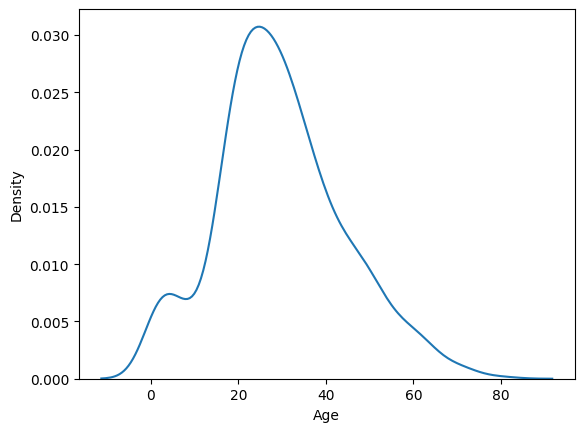

In [113]:
sns.kdeplot(df["Age"])

Explanation:

The kdeplot shows the data distribution of Age column. It is a little bit left skewed, but overall can be considered as normally distributed as most of it's data are beside the central area (the peak is very steep).

Distribution of Fare

<Axes: xlabel='Fare', ylabel='Density'>

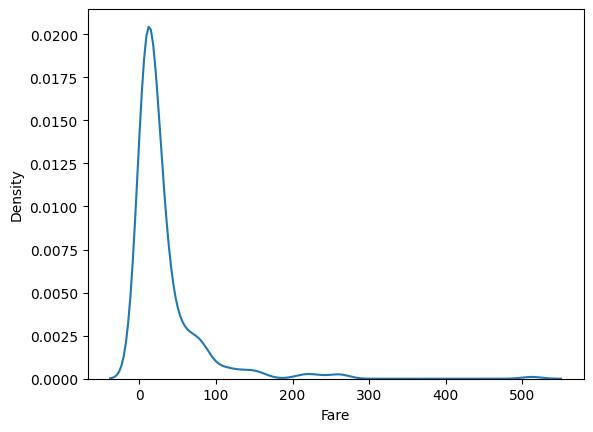

In [114]:
sns.kdeplot(df["Fare"])

Explanation: the whole dataset is skewed, no sign of bell curve in anyway. This is a left skewed dataset (long tail left). mode > mean > median.  

Maximum & Minimum of both Age & Fare's outlines  

In [115]:
# Z score (min, max)
# Fare
minimum_zscore_fare = X_train[abs(X_train['zscore_Fare']) <=3]['Fare'].max()
maximum_zscore_fare = X_train[abs(X_train['zscore_Fare']) <=3]['Fare'].min()
print(f"Minimum z score fare: {minimum_zscore_fare} \nMaximum z score fare: {maximum_zscore_fare}")
# Age
minimum_zscore_age = X_train[abs(X_train['zscore_Age']) <=3]['Age'].max()
maximum_zscore_age = X_train[abs(X_train['zscore_Age']) <=3]['Age'].min()
print(f"Minimum z score age: {minimum_zscore_age} \nMaximum z score age: {maximum_zscore_age}\n")

# IQR (min, max)
# Fare
minimum_IQR_fare = fare_outlier_IQR['Fare'].max()
maximum_IQR_fare = fare_outlier_IQR['Fare'].min()
print(f"Minimum IQR fare: {minimum_IQR_fare} \nMaximum IQR fare: {maximum_IQR_fare}")
# Age
minimum_IQR_age = age_outlier_IQR['Age'].max()
maximum_IQR_age = age_outlier_IQR['Age'].min()
print(f"Minimum IQR age: {minimum_IQR_age} \nMaximum IQR age: {maximum_IQR_age}")

Minimum z score fare: 164.8667 
Maximum z score fare: 0.0
Minimum z score age: 65.0 
Maximum z score age: 0.42

Minimum IQR fare: 512.3292 
Maximum IQR fare: 65.0
Minimum IQR age: 80.0 
Maximum IQR age: 0.42


### Data Explore and Basic Observation

## Age:
- almost normally distributed data
- Detection method:
  - z score:
    - 5 samples
    - range: (0.42-65) years.
    - Observation: Yes, above 65 age is genuinely rare.
  - IQR:
    - 51 samples
    - range: (42-80) years.
    - observation: 0 to 42 has got a not negligible huge chunk.  
- Decision:
  - Detection: Z score is the better one for this column
  - Handling: as only 5 samples, so just delete them.

## Fare:
- heavily right skewed data.
- Detection method:
  - z score:
    - 17 outliers
    - range: (164-512)
    - Observation: Captures extreme (512) but missed the broader skewed tail.
  - IQR:
    - 96 outliers
    - range: (65-512.33)
    - Observation: captures the broader upper_class tail or the right (more ppl paid more) skewness.
- Decision:
  - Detection: IQR is better for Fare column.
  - Handling: can't delete 96 outliers, so cap them. (Winsorization method)

Dropping zscore age and fare cols

In [116]:
X_train.head()
X_train.drop(['zscore_Age','zscore_Fare'],axis=1 , inplace=True)
X_train.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,cabin_missing_indicator
331,first,male,45.5,0,0,28.5000,C124,S,False
733,second,male,23.0,0,0,13.0000,Missing,S,True
382,third,male,32.0,0,0,7.9250,Missing,S,True
704,third,male,26.0,1,0,7.8542,Missing,S,True
813,third,female,6.0,4,2,31.2750,Missing,S,True
